# Campeón y retador: bootstrap pareado del Brier y desacuerdo de grados

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema; el cuaderno 03 del tema 01 para las luces
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir por qué un validador compara el modelo en uso (el campeón) con un modelo más simple o distinto (el retador) sobre las mismas filas, y qué piden SS1/23 y la guía del BCE de esa comparación;
- calcular la diferencia de Brier con un intervalo bootstrap **pareado**, explicar por qué importa el pareo y leer su luz;
- medir cuántos deudores cambian de grado en dos o más escalones entre los dos modelos;
- leer la comparación de retadores versionada del caso C02 (un campeón de scorecard contra cinco retadores sobre empresas polacas), reconstruir sus filas de Brier con el motor y decir qué justifica y qué no justifica una ganancia de discriminación.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Poner el pipeline en la ruta de importación para la escala maestra, importar los paquetes e imprimir sus versiones
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.scores import LogisticPortfolio
from riskvalidation.ml import challenger as ch
from riskvalidation.ml.challenger import PairedBrier
from riskvalidation.validation import discrimination as disc
from riskvalidation.validation import ml as vml
from scipy import special

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.core.calibration import MASTER_SCALE_UPPER

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

- **Una cartera logística del motor** (`riskvalidation.generators.scores.LogisticPortfolio`): 4.000 deudores con tres covariables correlacionadas, una PD verdadera logística en ellas (`pd_true`) y una PD del modelo (`pd`) que el generador distorsiona con una pendiente y un intercepto de calibración que elegimos. El campeón es ese modelo distorsionado; los retadores son la PD verdadera y una versión deliberadamente optimista de ella. Sintética, generada desde una semilla, sin clase de licencia.
- **La escala maestra** del pipeline (`pipeline.core.calibration`): doce grados cuyas cotas superiores crecen por un factor 1,5 desde 1%. Es el mismo lector que usa el tema 01.
- **La comparación de retadores versionada del caso C02** (`data/derived/C02/h2.json`; propietario: este repositorio, derivada de los datos de quiebras polacas de UCI, CC BY 4.0, clase mirror-allowed): el horizonte de dos años, una reserva estratificada bloqueada de 2.938 empresas con 155 quiebras, una scorecard como campeón (peldaño P1) y cinco retadores (una logística L1, una logística con árbol lineal por tramos, un EBM y dos modelos de árboles potenciados). El pipeline ajustó los modelos; este cuaderno lee sus filas de comparación e imprime la versión del motor que las horneó.

In [2]:
# Abrir la comparación versionada e imprimir el motor que la horneó, la partición y el campeón
h2 = json.loads((ROOT / "data" / "derived" / "C02" / "h2.json").read_text(encoding="utf-8"))
print("horneado con riskvalidation", h2["provenance"]["riskvalidation_version"])
split = h2["outputs"]["split"]
print("protocolo:", split["protocol"], "| filas de reserva", split["holdout_rows"], "| eventos de reserva", split["holdout_events"])
print("campeón:", h2["outputs"]["challenger"][0]["champion"], "| retadores:", len(h2["outputs"]["challenger"]))

horneado con riskvalidation 0.8.1
protocolo: locked-stratified-holdout | filas de reserva 2938 | eventos de reserva 155
campeón: h2-P1-scorecard | retadores: 5


## Método

SS1/23 pide comparaciones con retadores (principio 3.3(b)(iii)), y la guía del BCE pide que la complejidad de un modelo se justifique por una ganancia de desempeño sobre un referente más simple, como un modelo lineal generalizado (párrafo 60). El motor ofrece tres lecturas de "qué tan distinto, y cuánto mejor".

### Paso 1: la diferencia de Brier con un bootstrap pareado

El puntaje de Brier es el error cuadrático medio de una probabilidad, $B = \frac{1}{n}\sum_i (p_i - y_i)^2$, que premia juntas la calibración y la nitidez (una pregunta distinta del AUC, que solo ordena). Para el campeón $p^{cm}$ y un retador $p^{ch}$ puntuados sobre los **mismos deudores**, se define la diferencia por deudor y la diferencia de Brier (retador menos campeón; negativo es mejor para el retador):

$$d_i = (p^{ch}_i - y_i)^2 - (p^{cm}_i - y_i)^2, \qquad \Delta B = \frac{1}{n}\sum_{i=1}^{n} d_i .$$

El intervalo remuestrea los **deudores** $B$ veces con reemplazo, conjuntamente para ambos modelos (los mismos índices remuestreados puntúan a los dos), toma $\Delta B^{(b)}$ de cada remuestra e informa los percentiles 2,5 y 97,5. Remuestrear conjuntamente conserva el pareo: el campeón y el retador cometen errores sobre los mismos deudores, que están correlacionados, y la varianza de la diferencia es menor que la suma de las dos varianzas. El `bootstrap_ci` anterior del motor remuestrea un solo puntaje y no puede hacerlo. La luz es ámbar cuando todo el intervalo queda **sobre** cero (el retador es mediblemente peor que el campeón) y verde en otro caso; un retador mejor nunca es un hallazgo contra el campeón, y la prueba no tiene umbral de política.

La celda siguiente saca la cartera e imprime el Brier del campeón, de la PD verdadera y de un retador optimista (la PD verdadera rebajada en 0,8 en log-odds).

In [3]:
# Sacar 4.000 deudores: el campeón es la PD distorsionada del modelo, los retadores son la PD verdadera y una versión optimista
portfolio = LogisticPortfolio(n=4000, intercept=-2.0, calibration_slope=0.5, calibration_intercept=-0.3)
draw = portfolio.draw(np.random.default_rng(1))
y = draw["defaults"]
champion = draw["pd"]
better = draw["pd_true"]
optimistic = special.expit(special.logit(better) - 0.8)
for label, p in (("campeón (distorsionado)", champion), ("retador, PD verdadera", better), ("retador, optimista", optimistic)):
    print(f"{label:34s} Brier {np.mean((p - y) ** 2):.5f} | PD media {p.mean():.4f} | AUC {float(disc.disc_auc(p, y).metric):.4f}")
print("tasa de incumplimiento observada:", round(float(y.mean()), 4))

campeón (distorsionado)            Brier 0.12789 | PD media 0.2296 | AUC 0.7762
retador, PD verdadera              Brier 0.12234 | PD media 0.1683 | AUC 0.7762
retador, optimista                 Brier 0.13240 | PD media 0.0926 | AUC 0.7762
tasa de incumplimiento observada: 0.176


Los dos retadores tienen el mismo orden que su base (un desplazamiento constante en log-odds no cambia el orden), así que el AUC no distingue al retador optimista de la PD verdadera; el puntaje de Brier sí. La celda siguiente corre el bootstrap pareado con 1.000 remuestras para ambos y llama a la prueba del motor, y luego muestra qué compra el pareo: el error estándar de la diferencia de Brier a partir de las diferencias pareadas por deudor contra el que sale de tratar los dos puntajes de Brier como independientes.

In [4]:
# El bootstrap pareado y la luz del motor para cada retador, luego el error estándar con y sin pareo
results = {}
for label, p in (("PD verdadera", better), ("optimista", optimistic)):
    boot = ch.paired_brier_bootstrap(champion, p, y, n_boot=1000, seed=3)
    row = vml.challenger_brier("retador", boot)
    results[label] = boot
    print(f"{label:14s} ΔBrier {boot.diff:+.5f} | 95% [{boot.lo:+.5f}, {boot.hi:+.5f}] | n_boot {boot.n_boot} | luz {row.light.value}")
d = (better - y) ** 2 - (champion - y) ** 2
paired_se = d.std(ddof=1) / np.sqrt(len(d))
unpaired_se = np.sqrt(((better - y) ** 2).var(ddof=1) + ((champion - y) ** 2).var(ddof=1)) / np.sqrt(len(d))
print(f"error estándar de la diferencia, pareado {paired_se:.5f} | tratado como independiente {unpaired_se:.5f}")
same = ch.paired_brier_bootstrap(champion, champion, y, n_boot=200, seed=3)
print("pronósticos idénticos:", same.diff, same.lo, same.hi)

PD verdadera   ΔBrier -0.00555 | 95% [-0.00719, -0.00391] | n_boot 1000 | luz green
optimista      ΔBrier +0.00451 | 95% [+0.00137, +0.00768] | n_boot 1000 | luz amber
error estándar de la diferencia, pareado 0.00086 | tratado como independiente 0.00449
pronósticos idénticos: 0.0 0.0 0.0


### Paso 2: desacuerdo de grados

Un retador con mejor Brier puede igualmente asignar otros grados, y los grados son lo que usan las decisiones y el capital. El motor cuenta la proporción de deudores cuyos grados bajo dos vectores de PD difieren en al menos $m$ escalones (la regla del dossier usa 2):

$$\text{desacuerdo}_m = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\bigl[\, |g(p^{cm}_i) - g(p^{ch}_i)| \ge m \,\bigr], \qquad g(p) = \#\{\text{bordes} \le p\}.$$

La medida es simétrica en los dos modelos. Los bordes son las once cotas superiores interiores de la escala maestra. La celda siguiente la calcula para los tres vectores de PD con uno y con dos escalones.

In [5]:
# Proporción de deudores cuyo grado difiere en al menos uno y dos escalones, y la comprobación de simetría
edges = np.array(MASTER_SCALE_UPPER[:-1])
print("bordes interiores:", len(edges))
for label, p in (("PD verdadera", better), ("optimista", optimistic)):
    one = ch.grade_disagreement(champion, p, edges, notches=1)
    two = ch.grade_disagreement(champion, p, edges, notches=2)
    print(f"{label:14s} 1 escalón o más {one:.4f} | 2 escalones o más {two:.4f}")
print("simétrica:", ("sí" if ch.grade_disagreement(champion, better, edges) == ch.grade_disagreement(better, champion, edges) else "no"))

bordes interiores: 11
PD verdadera   1 escalón o más 0.8085 | 2 escalones o más 0.4903
optimista      1 escalón o más 0.9768 | 2 escalones o más 0.8520
simétrica: sí


### Paso 3: la comparación de discriminación (DeLong)

La prueba pareada de dos AUC sobre las mismas filas es la de DeLong (el `disc_delong` del motor). Recibe ambos vectores de riesgo y los resultados y devuelve el AUC de cada uno, su diferencia, la varianza de la diferencia y un valor p de dos colas. Solo puede comparar ordenamientos que difieren: el campeón y la PD verdadera de la planta tienen el mismo orden (la distorsión es monótona), así que la varianza de la diferencia es cero y el motor devuelve `not_evaluated` en lugar de un número. La comparación de Brier del paso 1 es la que ve la calibración. Para tener un orden distinto, la celda siguiente agrega un tercer pronóstico, un referente más simple que usa solo la primera covariable (el tipo de referente lineal generalizado que tiene en mente la guía del BCE), y corre DeLong contra ambos.

In [6]:
# Prueba de DeLong del campeón contra la PD verdadera y contra un referente más simple que usa solo la primera covariable
simple = special.expit(-2.0 + 0.8 * draw["x"][:, 0])
for label, p in (("PD verdadera", better), ("referente simple", simple)):
    t = disc.disc_delong(p, champion, y)
    z = "nan" if t.p_value is None else f"{t.statistic:.3f}"
    pv = "-" if t.p_value is None else f"{t.p_value:.3g}"
    print(f"{label:20s} AUC retador {t.extras['auc_1']:.4f} campeón {t.extras['auc_2']:.4f} | varianza de la diferencia {t.extras['variance']:.3e} | z {z} | p {pv} | luz {t.light.value}")
    print(f"{'':20s} Brier del retador {np.mean((p - y) ** 2):.5f} contra el del campeón {np.mean((champion - y) ** 2):.5f}")

PD verdadera         AUC retador 0.7762 campeón 0.7762 | varianza de la diferencia 0.000e+00 | z nan | p - | luz not_evaluated
                     Brier del retador 0.12234 contra el del campeón 0.12789
referente simple     AUC retador 0.7374 campeón 0.7762 | varianza de la diferencia 3.562e-05 | z -6.501 | p 7.99e-11 | luz red
                     Brier del retador 0.13105 contra el del campeón 0.12789


### Paso 4: la comparación versionada del caso C02

Para cada uno de los cinco retadores el pipeline escribió una fila de DeLong y una fila de Brier pareado. La celda siguiente reconstruye el `PairedBrier` del motor desde la diferencia y el intervalo versionados, llama a la prueba del motor y compara su luz con la versionada. Imprime la diferencia de AUC con su valor p de DeLong, la diferencia de Brier con su intervalo y el desacuerdo de grados, para cada retador.

In [7]:
# Reconstruir el objeto de Brier pareado de cada retador versionado, llamar a la prueba del motor y comparar con la luz versionada
committed = {t["model_id"]: t for t in h2["tests"] if t["test_id"] == "ml.challenger_brier"}
print(f'{"retador":16s} {"ΔAUC":>8s} {"p DeLong":>10s} {"ΔBrier":>9s} {"intervalo de 95%":>22s} {"grados ≥2":>11s} luz igual')
for row in h2["outputs"]["challenger"]:
    b = row["brier_diff_ci"]
    again = vml.challenger_brier(row["challenger"], PairedBrier(row["brier_diff"], b["lo"], b["hi"], 1000))
    old = committed[row["challenger"]]
    print(f'{row["challenger"]:16s} {row["auc_diff"]:8.4f} {row["delong_p_value"]:10.2e} {row["brier_diff"]:9.5f} [{b["lo"]:+.5f}, {b["hi"]:+.5f}] {row["grade_disagreement_share"]:11.4f} {again.light.value:5s} {"sí" if again.light.value == old["light"] else "no"}')

retador              ΔAUC   p DeLong    ΔBrier       intervalo de 95%   grados ≥2 luz igual
h2-P2a-l1          0.0248   1.52e-04  -0.00077 [-0.00183, +0.00027]      0.1290 green sí
h2-P2b-pltr        0.0936   6.46e-11  -0.01066 [-0.01399, -0.00739]      0.5000 green sí
h2-P3-ebm          0.1117   1.24e-14  -0.01714 [-0.02075, -0.01382]      0.5000 green sí
h2-P4-lightgbm     0.1128   6.26e-16  -0.01507 [-0.01901, -0.01142]      0.4952 green sí
h2-P4-xgboost      0.1023   3.79e-14  -0.01280 [-0.01664, -0.00891]      0.4973 green sí


### Paso 5: la evidencia, dibujada

Izquierda: la diferencia de Brier y su intervalo pareado para los dos retadores de la planta. Derecha: la diferencia de AUC contra la diferencia de Brier para los cinco retadores versionados, con la proporción de deudores que cambia dos grados como etiqueta de cada punto.

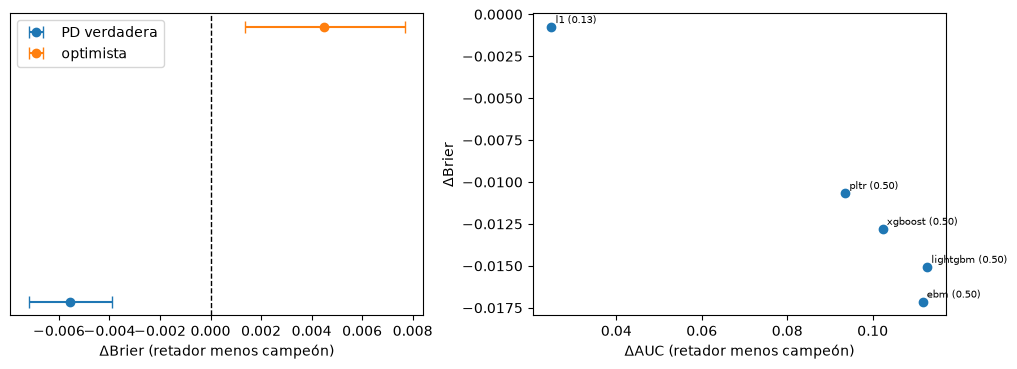

In [8]:
# Izquierda: intervalos pareados de los retadores de la planta; derecha: ganancia de AUC versionada contra ganancia de Brier, etiquetada por desacuerdo de grados
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.8))
for k, (label, boot) in enumerate(results.items()):
    left.errorbar(boot.diff, k, xerr=[[boot.diff - boot.lo], [boot.hi - boot.diff]], fmt="o", capsize=4, label=label)
left.axvline(0.0, color="black", linestyle="--", linewidth=1)
left.set_yticks([])
left.set_xlabel("ΔBrier (retador menos campeón)")
left.legend()
for row in h2["outputs"]["challenger"]:
    right.scatter(row["auc_diff"], row["brier_diff"], color="tab:blue")
    right.annotate(f'{row["challenger"].split("-")[-1]} ({row["grade_disagreement_share"]:.2f})', (row["auc_diff"], row["brier_diff"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
right.set_xlabel("ΔAUC (retador menos campeón)")
right.set_ylabel("ΔBrier")
fig.tight_layout()
plt.show()

## Resultados

- **Un mejor AUC y un mejor Brier son hallazgos distintos.** Los tres pronósticos de la planta ordenan a los deudores igual (AUC 0,7762 en todos), así que DeLong no puede comparar al campeón con la PD verdadera: la varianza de la diferencia es cero y el motor devuelve `not_evaluated` en lugar de un número. El puntaje de Brier sí los separa: la PD verdadera mejora al campeón distorsionado en 0,00555 (intervalo de -0,00719 a -0,00391, verde), y el retador optimista, cuyo orden es el mismo, es peor en 0,00451 (intervalo de +0,00137 a +0,00768, ámbar), porque todo el intervalo queda sobre cero.
- **El pareo es lo que estrecha el intervalo.** El error estándar de la diferencia de Brier es 0,00086 con las diferencias pareadas por deudor y 0,00449 si los dos puntajes de Brier se tratan como independientes: cinco veces mayor, lo bastante ancho para esconder la mejora de la PD verdadera. Pronósticos idénticos dan una diferencia de 0 y un intervalo de ancho cero.
- **Un modelo puede diferir en grado sin diferir en orden.** La PD verdadera deja al 49,03% de los deudores a dos grados o más del campeón (80,85% a uno o más), y el retador optimista al 85,20% (97,68% a uno o más). Ninguno cambia el AUC. La medida es simétrica, y es la que le dice a un dueño del negocio cuántas decisiones se moverían.
- **Un referente más simple se lee igual.** El referente con una covariable ordena peor (AUC 0,7374 contra 0,7762, z = -6,501, p = 7,99e-11, rojo en la luz de DeLong del motor) y su Brier también es mayor (0,13105 contra 0,12789).
- **La comparación versionada de C02 separa lo que justifica una ganancia.** Los cinco retadores tienen un AUC mayor que la scorecard (de +0,0248 a +0,1128, todo valor p de DeLong bajo 2e-4) y una luz de Brier pareado verde. Pero el intervalo de Brier de la logística L1, de -0,00183 a +0,00027, contiene el cero: su ganancia de discriminación no viene con una ganancia de calibración medible, y el 12,90% de los deudores cambia dos grados o más. Los otros cuatro tienen intervalos enteramente bajo cero (de -0,01066 para la logística con árbol por tramos a -0,01714 para el EBM) y cerca de la mitad de los deudores (de 49,52% a 50,00%) cambia dos grados o más. El motor reconstruido desde los intervalos versionados da la luz versionada en las cinco filas; todas se hornearon con riskvalidation 0.8.1.

Lo que los resultados no muestran: la planta es sintética y su campeón está distorsionado a propósito; una luz de Brier verde dice que el retador no es peor de forma medible, no que deba reemplazar al campeón; el párrafo 60 del BCE pide que la complejidad se justifique por una ganancia de desempeño, y el tamaño de la ganancia que la justifica es un juicio del validador, no un umbral del motor.

## Resumen

- La diferencia de Brier entre un retador y el campeón se estima por bootstrap remuestreando los deudores conjuntamente para ambos modelos; el pareo vuelve el intervalo unas cinco veces más estrecho aquí, y la luz es ámbar solo cuando todo el intervalo queda sobre cero.
- El desacuerdo de grados cuenta los deudores cuyos grados difieren en al menos dos escalones; un modelo puede dejar el AUC sin cambio y mover la mitad de los grados.
- DeLong compara dos ordenamientos y no puede comparar dos pronósticos que ordenan igual; la comparación de Brier ve la calibración y la comparación de AUC ve el orden.
- En la comparación versionada de C02 todo retador mejora el AUC de forma significativa, la logística L1 lo hace sin una ganancia de Brier medible, y cerca de la mitad de los deudores cambia dos grados con los cuatro modelos más complejos.
- La comparación aporta la evidencia; si la ganancia justifica la complejidad (párrafo 60 del BCE, SS1/23) es un juicio del validador.

**Qué probar después.** El cuaderno 06 pasa del desempeño a la equidad: tasas de selección por grupo y las pruebas construidas sobre ellas.

## Referencias

- Bank of England PRA (2023), SS1/23 Principios de gestión del riesgo de modelo para bancos, principio 3.3(b)(iii) sobre comparaciones con retadores. https://www.bankofengland.co.uk/prudential-regulation/publication/2023/may/model-risk-management-principles-for-banks-ss
- BCE (2025), Guía de modelos internos, los párrafos sobre la aleatoriedad del entrenamiento, el sobreajuste, la explicabilidad y la justificación de la complejidad (43, 59, 60, 62, 64 a 66). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.supervisory_guide202507.en.pdf
- Zieba, M., Tomczak, S. K. y Tomczak, J. M., Polish companies bankruptcy data, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data
- PiML-Toolbox (Apache-2.0), pruebas de resultados WeakSpot, Overfit, Reliability, Robustness y Resilience; Sudjianto et al. (2023), arXiv 2305.04214. https://github.com/SelfExplainML/PiML-Toolbox